# Ecosystem Structure from UAVSAR Polarimetric Radar and NISAR

## Overview

In May 2026, [AVUELO](https://www.earthdata.nasa.gov/data/projects/avuelo) flew NASA's Uninhabited Aerial Vehicle Synthetic Aperture Radar ([UAVSAR](https://www.earthdata.nasa.gov/data/instruments/uavsar)) over Panama. UAVSAR is an L-band radar (wavelength 23.8 cm). Unlike the optical imagery of AVIRIS-3, which sees the leaves at the top of the canopy, L-band radar waves penetrate into the canopy and interact with branches, trunks, and the ground or water below. Radar measurements are therefore sensitive to the structure of vegetation and to its condition, such as moisture and flooding. They are also not affected by clouds.

UAVSAR is polarimetric SAR - it transmits and receives both horizontally (H) and vertically (V) polarized waves. Different scattering mechanisms affect the polarizations differently:

| Scattering mechanism | Typical surfaces | Polarimetric signature |
|---|---|---|
| Surface scattering | Open water, bare soil, short grass | Strong HH and VV, weak HV, HH and VV in phase |
| Volume scattering | Forest canopies, mangrove crowns | Strong HV (cross-polarized) |
| Double-bounce scattering | Tree trunks over water (flooded forests, mangroves), buildings | Strong HH, HH and VV about 180 degrees out of phase |

In this tutorial, we use the NASA's [UAVSAR Polarimetric SAR (PolSAR) product](https://doi.org/10.5067/7PEQV8SVR4DM) to compare the radar signatures of two Panamanian ecosystems:

1. the old-growth tropical forest of **Barro Colorado Island (BCI)**
2. the **mangroves** and coastal wetlands of **Parita Bay**, on the Pacific coast

We will:

- search the AVUELO UAVSAR flight lines and choose lines by their coverage
- read only the part of a large PolSAR file that covers a study area
- make backscatter images and a Pauli color composite of the scattering mechanisms
- compute structure indicators: cross-polarized backscatter, the radar vegetation index (RVI), and the co-polarized phase difference and coherence
- compare ecosystems using the [ESA WorldCover](https://esa-worldcover.org/) land cover map, accounting for the incidence angle
- fetch the colocated ([NISAR satellite radar](https://www.earthdata.nasa.gov/data/platforms/space-based-platforms/nisar) data and compare it with UAVSAR

## Requirements

- A NASA [Earthdata Login](https://urs.earthdata.nasa.gov/) account
- See the [prerequisites](../../docs/prerequisites.md) page for setup instructions.

## Import Libraries

In [1]:
import re
import earthaccess
import h5py
import pyproj
import numpy as np
import pandas as pd
import geopandas as gpd
import xarray as xr
import rioxarray
import matplotlib.pyplot as plt
from rasterio.enums import Resampling
from shapely.geometry import Polygon, box
import warnings
warnings.filterwarnings('ignore')

# ESRI basemap for interactive maps
xyz = "https://server.arcgisonline.com/ArcGIS/rest/services/World_Imagery/MapServer/tile/{z}/{y}/{x}"
attr = "ESRI"

## Authentication
`earthaccess.login()` authenticates with your Earthdata Login credentials. If you have a `.netrc` file or `EARTHDATA_USERNAME` and `EARTHDATA_PASSWORD` environment variables, login completes without a prompt. Searching does not require login, but streaming and downloading data do.

In [2]:
auth = earthaccess.login()

## Search the AVUELO UAVSAR Flight Lines

The UAVSAR PolSAR collection (`UAVSAR_POLSAR`) contains flights from many campaigns since 2008. We search for the 2026 flights over Panama. Each granule is one flight line.

In [3]:
granules = earthaccess.search_data(short_name='UAVSAR_POLSAR',
                                   bounding_box=(-83.1, 7.0, -77.1, 9.7), # Panama
                                   temporal=('2026-01-01', '2026-12-31'))
print(f"Flight lines found: {len(granules)}")

Flight lines found: 19


The granule metadata include a description of the site, and the bounding box of the flight line. We convert the granule metadata to a `geopandas` dataframe.

In [4]:
def granule_details(g):
    """Returns the granule, description, time, and size of a UAVSAR flight line."""
    umm = g['umm']
    attrs = {a['Name']: a['Values'][0] for a in umm.get('AdditionalAttributes', [])}
    return {'granule': umm['GranuleUR'],
            'site': attrs.get('SITE_DESCRIPTION'),
            'start_time': umm['TemporalExtent']['RangeDateTime']['BeginningDateTime'][:16],
            'size_gb': round(g['size'] / 1024, 1)}

gdf = gpd.GeoDataFrame([granule_details(g) for g in granules],
                         geometry=gpd.GeoSeries(granules, crs='EPSG:4326'))
gdf[['granule', 'site', 'start_time', 'size_gb']]

,granule,site,start_time,size_gb
0,PCanal_13503_26007_000_260505_L090_CX_01,"Barro Colorado Island, Panama",2026-05-05T13:05,10.5
1,PanCan_20012_26007_004_260505_L090_CX_01,"Panama Canal forests, Panama",2026-05-05T13:31,3.5
2,PanCaA_20033_26007_005_260505_L090_CX_01,"Panama Canal forests, Panama",2026-05-05T13:51,3.5
3,PanCaB_20034_26007_006_260505_L090_CX_01,"Panama Canal forests, Panama",2026-05-05T14:11,3.5
4,PanCaC_20035_26007_007_260505_L090_CX_01,"Panama Canal forests, Panama",2026-05-05T14:31,3.5
5,PanCaD_20036_26007_008_260505_L090_CX_01,"Panama Canal forests, Panama",2026-05-05T14:51,3.5
6,PanCaE_20037_26007_009_260505_L090_CX_01,"Panama Canal forests, Panama",2026-05-05T15:11,3.5
7,PanCaF_20038_26007_010_260505_L090_CX_01,"Panama Canal forests, Panama",2026-05-05T15:31,3.5
8,PanCaG_20039_26007_011_260505_L090_CX_01,"Panama Canal forests, Panama",2026-05-05T15:52,3.5
9,PanCaH_20040_26007_012_260505_L090_CX_01,"Panama Canal forests, Panama",2026-05-05T16:11,3.5


The flight lines are named `site_HHHCC_YYFFF_DDD_YYMMDD_L090_CX_VV`, where `site` is a site code, `HHH` is the heading of the aircraft in degrees, `CC` is a counter, `YYFFF` is the year and flight number, `DDD` is the data take number, `YYMMDD` is the date, `L090` is the L-band with a 90 degrees antenna steering, `CX` means that cross-talk calibration was applied, and `VV` is the processing version.

We plot the above as granule bounding boxes over a base map.

In [5]:
gdf.explore(column='site', tiles=xyz, attr=attr, tooltip=['granule', 'site', 'start_time'],
              style_kwds={'fillOpacity': 0.3, 'weight': 2})

## Files in a Flight Line Granule

Each flight line granule contains multiple files. The PolSAR products contain the elements of the 3×3 **polarimetric covariance matrix**, averaged over several pixels:

| File | Content | Data type |
|---|---|---|
| `*HHHH*.grd`, `*HVHV*.grd`, `*VVVV*.grd` | Power of the HH, HV, and VV channels: <\|S<sub>HH</sub>\|<sup>2</sup>>, <\|S<sub>HV</sub>\|<sup>2</sup>>, <\|S<sub>VV</sub>\|<sup>2</sup>> | float32 |
| `*HHHV*.grd`, `*HHVV*.grd`, `*HVVV*.grd` | Cross products between channels, e.g. <S<sub>HH</sub>S<sub>VV</sub>*> | complex64 |
| `*.mlc` | The same six products in the radar (slant range) geometry | float32 / complex64 |
| `*.hgt`, `*.inc`, `*.slope` | Terrain height (m), local incidence angle (radians), and terrain slope, on the `.grd` grid | float32 |
| `*.ann` | Annotation: text file with all metadata | text |
| `*.gif`, `*.kmz` | Quick-look image and Google Earth overlay | image |

The `.grd` files are projected on a latitude/longitude grid, which are raw binary files with no header. The grid size and location are in the annotation file. See the [PolSAR format description](https://uavsar.jpl.nasa.gov/science/documents/polsar-format.html) for details. 

Let's look at the quick-look image of a flight line. Red, green, and blue are the HH, HV, and VV power.

In [6]:
pchame = [g for g in granules if g['umm']['GranuleUR'].startswith('pchame')][0]
pchame

Collection: {'ShortName': 'UAVSAR_POLSAR', 'Version': '1'}
Spatial coverage: {'HorizontalSpatialDomain': {'Geometry': {'GPolygons': [{'Boundary': {'Points': [{'Latitude': 8.10198, 'Longitude': -80.57741}, {'Latitude': 8.22829, 'Longitude': -80.35846}, {'Latitude': 8.40609, 'Longitude': -80.46177}, {'Latitude': 8.27973, 'Longitude': -80.68079}, {'Latitude': 8.10198, 'Longitude': -80.57741}]}}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2026-05-06T16:36:48Z', 'EndingDateTime': '2026-05-06T16:39:10Z'}}
Size(MB): 2229.744562149048
Data: ['https://cumulus.asf.earthdatacloud.nasa.gov/PRODUCTS/UAVSAR/UAVSAR_POLSAR/pchame_06021_26008_022_260506_L090_CX_01/pchame_06021_26008_022_260506_L090HHHH_CX_01.grd', 'https://cumulus.asf.earthdatacloud.nasa.gov/PRODUCTS/UAVSAR/UAVSAR_POLSAR/pchame_06021_26008_022_260506_L090_CX_01/pchame_06021_26008_022_260506_L090HHHH_CX_01.mlc', 'https://cumulus.asf.earthdatacloud.nasa.gov/PRODUCTS/UAVSAR/UAVSAR_POLSAR/pchame_06021_26008_022_260506_L090_CX_01/pchame_06021_26008_022_260506_L090HHHV_CX_01.grd', 'https://cumulus.asf.earthdatacloud.nasa.gov/PRODUCTS/UAVSAR/UAVSAR_POLSAR/pchame_06021_26008_022_260506_L090_CX_01/pchame_06021_26008_022_260506_L090HHHV_CX_01.mlc', 'https://cumulus.asf.earthdatacloud.nasa.gov/PRODUCTS/UAVSAR/UAVSAR_POLSAR/pchame_06021_26008_022_260506_L090_CX_01/pchame_06021_26008_022_260506_L090HHVV_CX_01.grd', 'https://cumulus.asf.earthdatacloud.nasa.gov/PRODUCTS/UAVSAR/UAVSAR_POLSAR/pchame_06021_26008_022_260506_L090_CX_01/pchame_06021_26008_022_260506_L090HHVV_CX_01.mlc', 'https://cumulus.asf.earthdatacloud.nasa.gov/PRODUCTS/UAVSAR/UAVSAR_POLSAR/pchame_06021_26008_022_260506_L090_CX_01/pchame_06021_26008_022_260506_L090HVHV_CX_01.grd', 'https://cumulus.asf.earthdatacloud.nasa.gov/PRODUCTS/UAVSAR/UAVSAR_POLSAR/pchame_06021_26008_022_260506_L090_CX_01/pchame_06021_26008_022_260506_L090HVHV_CX_01.mlc', 'https://cumulus.asf.earthdatacloud.nasa.gov/PRODUCTS/UAVSAR/UAVSAR_POLSAR/pchame_06021_26008_022_260506_L090_CX_01/pchame_06021_26008_022_260506_L090HVVV_CX_01.grd', 'https://cumulus.asf.earthdatacloud.nasa.gov/PRODUCTS/UAVSAR/UAVSAR_POLSAR/pchame_06021_26008_022_260506_L090_CX_01/pchame_06021_26008_022_260506_L090HVVV_CX_01.mlc', 'https://cumulus.asf.earthdatacloud.nasa.gov/PRODUCTS/UAVSAR/UAVSAR_POLSAR/pchame_06021_26008_022_260506_L090_CX_01/pchame_06021_26008_022_260506_L090VVVV_CX_01.grd', 'https://cumulus.asf.earthdatacloud.nasa.gov/PRODUCTS/UAVSAR/UAVSAR_POLSAR/pchame_06021_26008_022_260506_L090_CX_01/pchame_06021_26008_022_260506_L090VVVV_CX_01.mlc', 'https://cumulus.asf.earthdatacloud.nasa.gov/PRODUCTS/UAVSAR/UAVSAR_POLSAR/pchame_06021_26008_022_260506_L090_CX_01/pchame_06021_26008_022_260506_L090_CX_01.dat', 'https://cumulus.asf.earthdatacloud.nasa.gov/PRODUCTS/UAVSAR/UAVSAR_POLSAR/pchame_06021_26008_022_260506_L090_CX_01/pchame_06021_26008_022_260506_L090_CX_01.hgt', 'https://cumulus.asf.earthdatacloud.nasa.gov/PRODUCTS/UAVSAR/UAVSAR_POLSAR/pchame_06021_26008_022_260506_L090_CX_01/pchame_06021_26008_022_260506_L090_CX_01.inc', 'https://cumulus.asf.earthdatacloud.nasa.gov/PRODUCTS/UAVSAR/UAVSAR_POLSAR/pchame_06021_26008_022_260506_L090_CX_01/pchame_06021_26008_022_260506_L090_CX_01.slope']

## Choose Flight Lines by Their Coverage

The site names are useful, but they do not guarantee that a flight line covers a particular area. We check which lines cover the BCI 50-ha forest plot, using the plot outlines from `data/avuelo_forest_plots.geojson`. The file contains approximate outlines of the nine forest plots in the [AVUELO tree crown dataset](https://doi.org/10.3334/ORNLDAAC/2517). Each outline is made by drawing the smallest rectangle around the mapped tree crowns of the plot. 

In [7]:
# read geojson plot boundary
plots = gpd.read_file('data/avuelo_forest_plots.geojson')
# keep BCI p50 plot
p50 = plots[plots.plot_code == 'p50'].geometry.iloc[0]
# compute percent overlap and adding as new column to the dataframe
gdf['p50_coverage_pct'] = (100 * gdf.geometry.intersection(p50).area / p50.area).round()
gdf[['granule', 'site', 'p50_coverage_pct']]

,granule,site,p50_coverage_pct
0,PCanal_13503_26007_000_260505_L090_CX_01,"Barro Colorado Island, Panama",0.0
1,PanCan_20012_26007_004_260505_L090_CX_01,"Panama Canal forests, Panama",100.0
2,PanCaA_20033_26007_005_260505_L090_CX_01,"Panama Canal forests, Panama",100.0
3,PanCaB_20034_26007_006_260505_L090_CX_01,"Panama Canal forests, Panama",100.0
4,PanCaC_20035_26007_007_260505_L090_CX_01,"Panama Canal forests, Panama",100.0
5,PanCaD_20036_26007_008_260505_L090_CX_01,"Panama Canal forests, Panama",100.0
6,PanCaE_20037_26007_009_260505_L090_CX_01,"Panama Canal forests, Panama",100.0
7,PanCaF_20038_26007_010_260505_L090_CX_01,"Panama Canal forests, Panama",100.0
8,PanCaG_20039_26007_011_260505_L090_CX_01,"Panama Canal forests, Panama",100.0
9,PanCaH_20040_26007_012_260505_L090_CX_01,"Panama Canal forests, Panama",100.0


The four lines described as "Barro Colorado Island" (`PCanal_13503`) do not cover the 50-ha plot. BCI is just outside the edge of their swath. The ten lines described as "Panama Canal forests" all cover it. We use the first of them, `PanCan_20012_26007_004_260505_L090_CX_01`.

Separately for the mangroves, we use the line `pchame_06021_26008_022_260506_L090_CX_01`. It covers the coast of Parita Bay, near Aguadulce, about 100 km west of Punta Chame. This coast has extensive mangroves, salt flats, and shrimp ponds.

In [8]:
# defining sites flight lines and bounds
sites = {
    'BCI forest': {'line': 'PanCan_20012_26007_004_260505_L090_CX_01',
                   'bounds': (-79.875, 9.135, -79.825, 9.185)},  # west, south, east, north
    'Parita Bay mangroves': {'line': 'pchame_06021_26008_022_260506_L090_CX_01',
                             'bounds': (-80.56, 8.16, -80.43, 8.31)},
}
# adding granules from earthaccess search
for site in sites.values():
    site['granule'] = [g for g in granules if g['umm']['GranuleUR'] == site['line']][0]

# plot granule boundary in white
m = gdf[gdf.granule.isin([s['line'] for s in sites.values()])].explore(
    color='white', tiles=xyz, attr=attr, style_kwds={'fillOpacity': 0.05})
# plot sites boundary
gpd.GeoDataFrame({'site': list(sites)}, geometry=[box(*s['bounds']) for s in sites.values()],
                 crs='EPSG:4326').explore(m=m, column='site',
                                          style_kwds={'fillOpacity': 0.3})

## Read the Annotation File

The annotation file (`.ann`) is a text file parameter names and values. We download it and parse it into a dictionary. Let's look at the content of the file.

In [9]:
fs = earthaccess.get_fsspec_https_session()

def related_url(g, suffix):
    """Returns URL of a file of a granule with the given suffix."""
    return [u['URL'] for u in g['umm']['RelatedUrls']
            if u['URL'].startswith('https') and u['URL'].endswith(suffix)][0]

def read_annotation(g):
    """Reads a UAVSAR annotation file into a dictionary."""
    text = fs.cat_file(related_url(g, '.ann')).decode()
    ann = {}
    for line in text.splitlines():
        m = re.match(r'^([^;=]+?)\s*(\([^)]*\))?\s*=\s*([^;]*)', line)
        if m:
            ann[m.group(1).strip()] = m.group(3).strip()
    return text, ann

text, ann = read_annotation(sites['BCI forest']['granule'])
print(text)

; Parameter file for PanCan_20012_26007_004_260505_L090_CX_01
;
; Search for parameters/value rather than placement in file
;
; slc = single look complex slant range image
; mlc = multi look cross product slant range image
; dat = compressed stokes matrix of multi-looked data
; grd = ground range projected (equiangular) and multi-looked data
; hgt = digital elevation model (DEM) used during processing and ground projection
; inc = ground range local incidence angle, the angle between the surface normal and the radar line of sight 
; slope = ground range terrain slope containing the derivatives of the DEM in the East and North direction, used to compute the local incidence angle
; h5  = HDF5 file containing binary data products mlc, grd, hgt, inc, and slope
; slc_mag and slc_phase are derived from the same 8 bytes per pixel of the slc input file
; mlc_mag and mlc_phase are derived from the same 8 bytes per pixel of the complex mlc input files
; grd_mag and grd_phase are ground range pro

The keywords below describe the `.grd` grid: its size, and the latitude and longitude of the center of the upper-left pixel, and the pixel spacing in degrees. Other keywords describe the calibration: the backscatter values are "σ0 (sigma nought)" in linear power units, and they are not corrected for terrain slope (`Slope Calibration in GRD = No`).

In [10]:
keys = ['grd_pwr.set_rows', 'grd_pwr.set_cols', 'grd_pwr.row_addr', 'grd_pwr.col_addr',
        'grd_pwr.row_mult', 'grd_pwr.col_mult', 'val_endi', 'Center Wavelength',
        'Number of Range Looks in GRD', 'Number of Azimuth Looks in GRD',
        'Slope Calibration in GRD', 'Start Time of Acquisition']
# read ann for each site
for site, s in sites.items():
    s['ann'] = read_annotation(s['granule'])[1]
# filter ann content for the keywords and print
pd.DataFrame({site: [s['ann'][k] for k in keys]
              for site, s in sites.items()}, index=keys)

,BCI forest,Parita Bay mangroves
grd_pwr.set_rows,8466,5616
grd_pwr.set_cols,6079,5826
grd_pwr.row_addr,9.39514044,8.41022832
grd_pwr.col_addr,-80.0064,-80.68156512
grd_pwr.row_mult,-5.556e-05,-5.556e-05
grd_pwr.col_mult,5.556e-05,5.556e-05
val_endi,LITTLE ENDIAN,LITTLE ENDIAN
Center Wavelength,0.238403545E+02,0.238403545E+02
Number of Range Looks in GRD,3,3
Number of Azimuth Looks in GRD,12,12


## Read the GRD Files

A `.grd` file is a grid of `rows` × `cols` pixels, stored row by row. The pixels of a range of rows are therefore stored together in the file, and we can read them with a single HTTP request for that range of bytes, without downloading the whole file. We then keep only the columns of the study area. Pixels outside the radar swath are 0, which we set to NaN.

In [11]:
def grd_grid(ann):
    """Returns the grid size, upper-left pixel center, and pixel spacing of the grd files."""
    return (int(ann['grd_pwr.set_rows']), int(ann['grd_pwr.set_cols']),
            float(ann['grd_pwr.row_addr']), float(ann['grd_pwr.col_addr']),
            float(ann['grd_pwr.row_mult']), float(ann['grd_pwr.col_mult']))

def read_grd(g, ann, suffix, bounds, dtype='<f4'):
    """Reads the pixels of a grd file (e.g. 'HVHV_CX_01.grd') within bounds."""
    rows, cols, lat0, lon0, dlat, dlon = grd_grid(ann)
    west, south, east, north = bounds
    r0, r1 = max(0, int((north - lat0) / dlat)), min(rows, int((south - lat0) / dlat) + 1)
    c0, c1 = max(0, int((west - lon0) / dlon)), min(cols, int((east - lon0) / dlon) + 1)
    nbytes = np.dtype(dtype).itemsize
    url = [u for u in g.data_links() if u.endswith(suffix)][0]
    buf = fs.cat_file(url, start=r0 * cols * nbytes, end=r1 * cols * nbytes)
    data = np.frombuffer(buf, dtype=dtype).reshape(r1 - r0, cols)[:, c0:c1]
    da = xr.DataArray(np.where(data == 0, np.nan, data), dims=('y', 'x'),
                      coords={'y': lat0 + dlat * np.arange(r0, r1),
                              'x': lon0 + dlon * np.arange(c0, c1)})
    return da.rio.write_crs('EPSG:4326')

We read the three power products, the HH-VV cross product, and the local incidence angle for each study area. The incidence angle file uses a large negative fill value (-10,000 radians) outside the swath, which we remove.

In [12]:
for site, s in sites.items():
    g, ann, b = s['granule'], s['ann'], s['bounds']
    s['HHHH'] = read_grd(g, ann, 'HHHH_CX_01.grd', b)
    s['HVHV'] = read_grd(g, ann, 'HVHV_CX_01.grd', b)
    s['VVVV'] = read_grd(g, ann, 'VVVV_CX_01.grd', b)
    s['HHVV'] = read_grd(g, ann, 'HHVV_CX_01.grd', b, dtype='<c8')
    inc = np.degrees(read_grd(g, ann, '_CX_01.inc', b))
    s['inc'] = inc.where((inc >= 0) & (inc <= 90) & s['HHHH'].notnull())  # remove fill values
    print(f"{site}: {dict(s['HHHH'].sizes)}, incidence angle "
          f"{float(s['inc'].min()):.0f}-{float(s['inc'].max()):.0f} degrees")

BCI forest: {'y': 901, 'x': 900}, incidence angle 9-90 degrees
Parita Bay mangroves: {'y': 2701, 'x': 2341}, incidence angle 12-83 degrees


## Backscatter Images

Backscatter is usually displayed in decibels (dB): σ0<sub>dB</sub> = 10 log<sub>10</sub>(σ0).

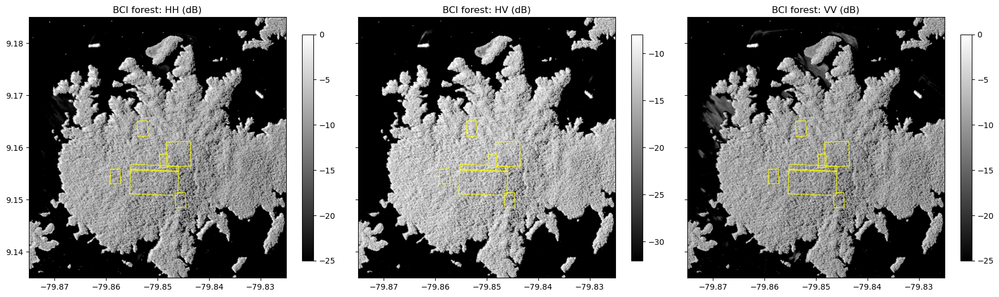

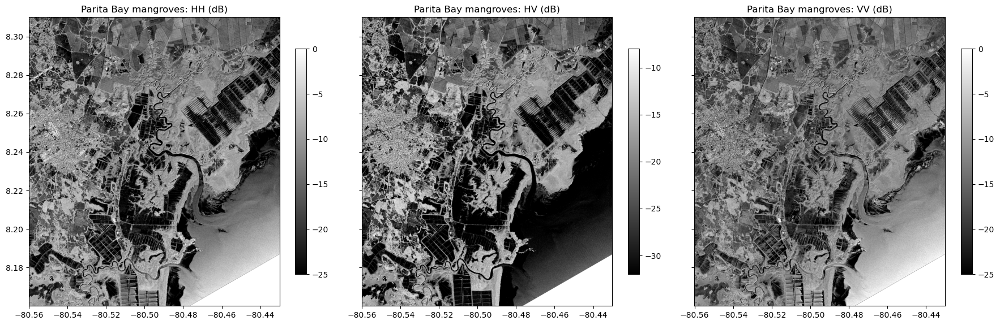

In [13]:
def db(x):
    return 10 * np.log10(x)

def extent(da):
    return [float(da.x.min()), float(da.x.max()),
            float(da.y.min()), float(da.y.max())]

for site, s in sites.items():
    fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
    for ax, term, vmin, vmax in zip(axes,
                                    ['HHHH', 'HVHV', 'VVVV'],
                                    [-25, -32, -25], [0, -8, 0]):
        im = ax.imshow(db(s[term]), extent=extent(s[term]),
                       vmin=vmin, vmax=vmax, cmap='gray')
        ax.set_title(f"{site}: {term[:2]} (dB)")
        fig.colorbar(im, ax=ax, shrink=0.7)
    # adding plot bounds for BCI forest 
    if site == 'BCI forest':
        for ax in axes:
            plots.boundary.plot(ax=ax, color='yellow', lw=0.8)
            ax.set_xlim(extent(s['HHHH'])[:2])
            ax.set_ylim(extent(s['HHHH'])[2:])
    plt.tight_layout()
    plt.show()

At BCI, the forest is bright in all three channels. The lake around the island is very dark, because its smooth water surface reflects the radar waves away from the sensor. The texture of the forest comes from the crowns and from the hills of the island, whose slopes facing the radar look brighter.

At Parita Bay, the mangroves along the tidal channels and the coast are bright in HV. The shrimp ponds and salt flats are dark rectangles. The urban area is bright in HH, because walls and the ground form corner reflectors. The sea is brighter in HH and VV, likely because of the wind moving the water surface, but remains dark in HV.

## Pauli Decomposition

The [Pauli decomposition](https://doi.org/10.1109/ICCIST67338.2025.11438514) separates the three basic scattering mechanisms. Each component is converted to dB and stretched between its 2nd and 98th percentiles.

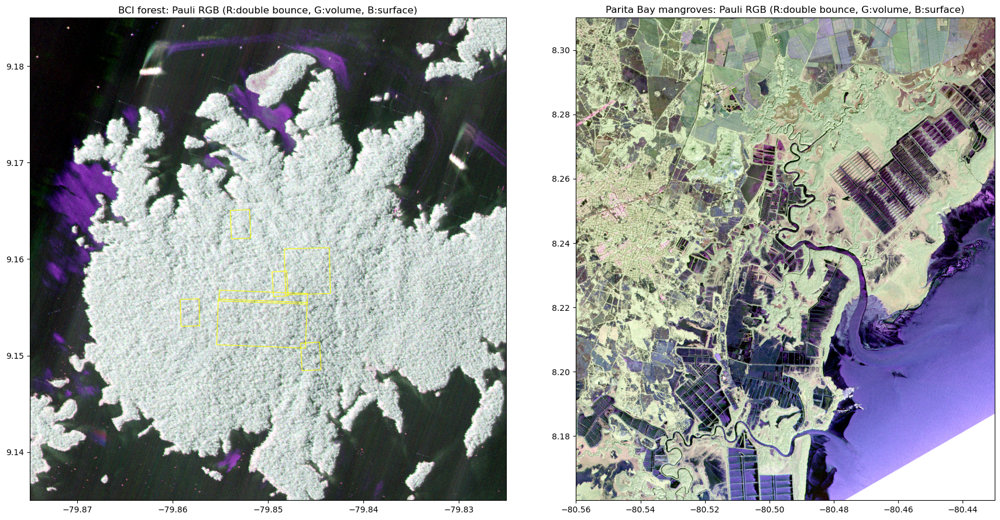

In [14]:
def stretch(x, lower=2, upper=98):
    """Percentile stretch of an array (in dB) to the 0-1 range."""
    lo, hi = np.nanpercentile(x, [lower, upper])
    return np.clip((x - lo) / (hi - lo), 0, 1)

def pauli_rgb(s):
    """Pauli RGB composite (R: double bounce, G: volume, B: surface)."""
    hh, hv, vv, hhvv = s['HHHH'], s['HVHV'], s['VVVV'], s['HHVV']
    double = (hh + vv - 2 * np.real(hhvv)) / 2
    volume = 2 * hv
    surface = (hh + vv + 2 * np.real(hhvv)) / 2
    rgb = np.dstack([stretch(db(x).values)
                     for x in (double, volume, surface)])
    rgb[np.isnan(rgb).any(axis=-1)] = 1
    return rgb

# plot
fig, axes = plt.subplots(1, 2, figsize=(18, 9))
for ax, (site, s) in zip(axes, sites.items()):
    ax.imshow(pauli_rgb(s), extent=extent(s['HHHH']))
    ax.set_title(f"{site}: Pauli RGB (R:double bounce, G:volume, B:surface)")
plots.boundary.plot(ax=axes[0], color='yellow', lw=0.8)
axes[0].set_xlim(extent(sites['BCI forest']['HHHH'])[:2])
axes[0].set_ylim(extent(sites['BCI forest']['HHHH'])[2:])
plt.tight_layout()
plt.show()

The forest of BCI is bright in all three components, a mix dominated by volume scattering. At Parita Bay, mangroves and other trees appear light green (volume scattering), the sea appears blue (surface scattering), and the buildings of Aguadulce appear pink-red (double bounce). The water of the shrimp ponds is dark, because it reflects little energy back to the radar.

## Structure Indicators

We compute three indicators of vegetation structure from the covariance products:

1. **Cross-polarized backscatter (HV)**: increases with the amount of woody material in the canopy (volume scattering), and is widely used to estimate aboveground biomass. At L-band, it saturates at high biomass (roughly 100–200 Mg/ha).
1. **Radar vegetation index (RVI)**: ~0 for a smooth surface, close to 1 for a fully random volume such as a dense canopy.
1. **Co-polarized phase difference and coherence**: the phase is around 0 degrees for surface scattering and around 180 degrees for double-bounce scattering. The coherence is high (close to 1) for simple scattering, such as from water, and low for the random scattering in canopies.

Over very dark surfaces, such as calm water, the backscatter is close to the noise level of the radar, and these ratios are not meaningful. We mask pixels where HH is below -25 dB.

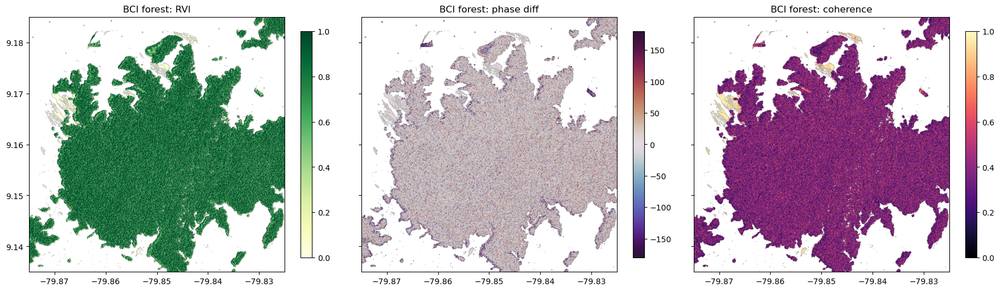

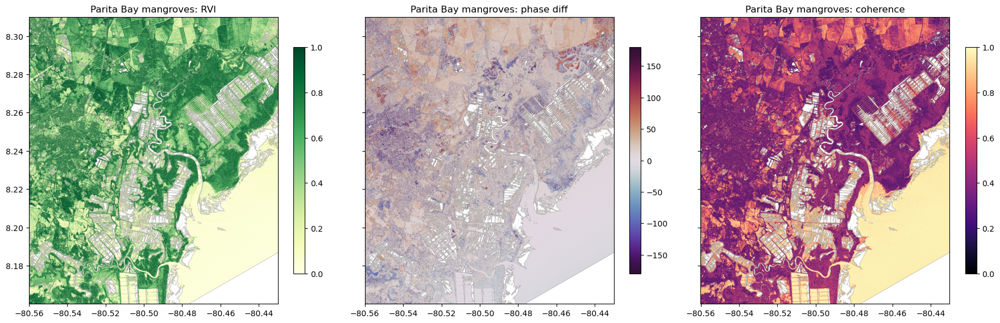

In [15]:
for site, s in sites.items():
    valid = db(s['HHHH']) > -25
    s['RVI'] = (8 * s['HVHV'] / (s['HHHH'] + s['VVVV']
                                 + 2 * s['HVHV'])).where(valid)
    s['phase_diff'] = xr.apply_ufunc(lambda c: np.degrees(np.angle(c)),
                                     s['HHVV']).where(valid)
    s['coherence'] = (np.abs(s['HHVV']) /
                      np.sqrt(s['HHHH'] * s['VVVV'])).where(valid)

for site, s in sites.items():
    fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
    layers = [('RVI', 0, 1, 'YlGn'),
              ('phase_diff', -180, 180, 'twilight_shifted'),
              ('coherence', 0, 1, 'magma')]
    for ax, (name, vmin, vmax, cmap) in zip(axes, layers):
        im = ax.imshow(s[name], extent=extent(s[name]),
                       vmin=vmin, vmax=vmax, cmap=cmap)
        ax.set_title(f"{site}: {name.replace('_', ' ')}")
        fig.colorbar(im, ax=ax, shrink=0.7)
    plt.tight_layout()
    plt.show()

## Compare Ecosystems with a Land Cover Map

To compare ecosystems objectively, we use the [ESA WorldCover 2021](https://doi.org/10.5281/zenodo.7254221) land cover map (10 m resolution), which has a separate class for **mangroves**. The map is stored as Cloud Optimized GeoTIFF tiles. We use `rioxarray` to read just our study areas. We put the land cover on the UAVSAR grid with `reproject_match()`, using nearest-neighbor resampling.

In [16]:
worldcover_classes = {10: 'Tree cover', 20: 'Shrubland', 30: 'Grassland', 40: 'Cropland',
                      50: 'Built-up', 60: 'Bare/sparse vegetation', 70: 'Snow and ice',
                      80: 'Permanent water', 90: 'Herbaceous wetland', 95: 'Mangroves',
                      100: 'Moss and lichen'}

def worldcover(bounds, match):
    """ESA WorldCover 2021 land cover within bounds, on the grid of `match`."""
    west, south, east, north = bounds
    lat, lon = int(np.floor(south / 3) * 3), int(np.floor(west / 3) * 3)
    tile = f"{'N' if lat >= 0 else 'S'}{abs(lat):02d}{'E' if lon >= 0 else 'W'}{abs(lon):03d}"
    url = ('https://esa-worldcover.s3.eu-central-1.amazonaws.com/v200/2021/map/'
           f'ESA_WorldCover_10m_2021_v200_{tile}_Map.tif')
    lc = rioxarray.open_rasterio(url).squeeze(drop=True)
    lc = lc.rio.clip_box(west - 0.01, south - 0.01, east + 0.01, north + 0.01)
    return lc.rio.reproject_match(match, resampling=Resampling.nearest)

for site, s in sites.items():
    s['landcover'] = worldcover(s['bounds'], s['HHHH'])

We plot ESA landcover over our study area.

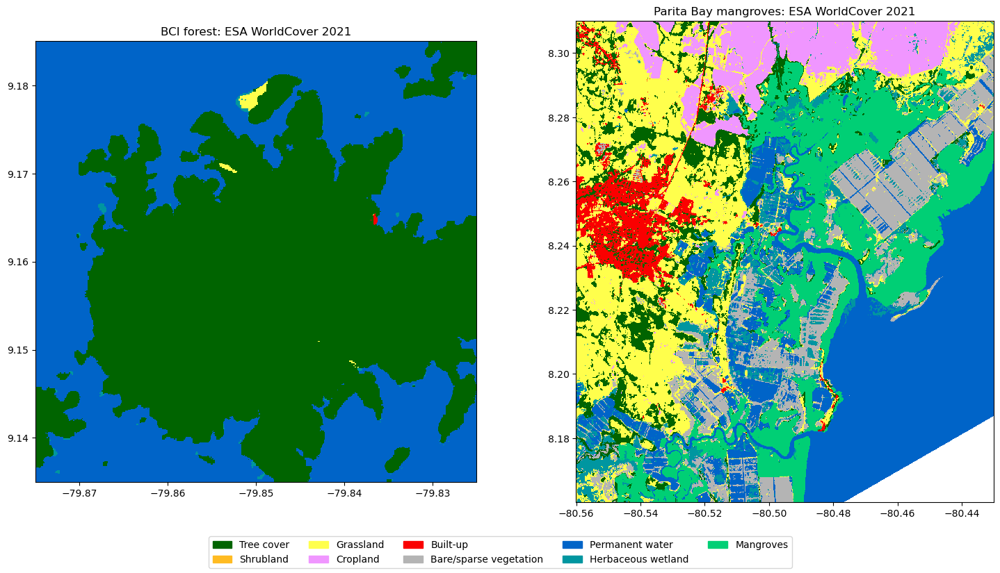

In [17]:
lc_colors = {10: '#006400', 20: '#ffbb22', 30: '#ffff4c', 40: '#f096ff', 50: '#fa0000',
             60: '#b4b4b4', 80: '#0064c8', 90: '#0096a0', 95: '#00cf75'}
codes = sorted(lc_colors)
cmap = plt.matplotlib.colors.ListedColormap([lc_colors[c] for c in codes])
norm = plt.matplotlib.colors.BoundaryNorm(np.array(codes + [100]) - 0.5, len(codes))

fig, axes = plt.subplots(1, 2, figsize=(18, 9))
for ax, (site, s) in zip(axes, sites.items()):
    lc = s['landcover'].where(s['HHHH'].notnull())
    ax.imshow(lc, extent=extent(lc), cmap=cmap, norm=norm, interpolation='nearest')
    ax.set_title(f"{site}: ESA WorldCover 2021")
handles = [plt.matplotlib.patches.Patch(color=lc_colors[c],
                                        label=worldcover_classes[c]) for c in codes]
fig.legend(handles=handles, loc='lower center', ncol=5)
plt.show()

We create a pandas dataframe to put the radar measurements of all pixels, with their land cover class and incidence angle.

In [18]:
frames = []
for site, s in sites.items():
    df = pd.DataFrame({
        'site': site,
        'land_cover': s['landcover'].values.ravel(),
        'incidence': s['inc'].values.ravel(),
        'HH_dB': db(s['HHHH']).values.ravel(),
        'HV_dB': db(s['HVHV']).values.ravel(),
        'VV_dB': db(s['VVVV']).values.ravel(),
        'RVI': s['RVI'].values.ravel(),
        'phase_diff': s['phase_diff'].values.ravel(),
        'coherence': s['coherence'].values.ravel(),
    })
    frames.append(df.dropna(subset=['HH_dB']))
pixels = pd.concat(frames, ignore_index=True)
pixels['land_cover'] = pixels.land_cover.map(worldcover_classes)
pixels.groupby(['site', 'land_cover']).size().rename('pixels').to_frame()

pixels
site                 land_cover                     
BCI forest           Built-up                    154
                     Grassland                  1725
                     Herbaceous wetland         1804
                     Permanent water          374437
                     Tree cover               432780
Parita Bay mangroves Bare/sparse vegetation   658837
                     Built-up                 253507
                     Cropland                 476114
                     Grassland               1309266
                     Herbaceous wetland       399395
                     Mangroves               1040736
                     Permanent water         1481821
                     Shrubland                   245
                     Tree cover               500240

### The effect of the incidence angle

The incidence angle is the angle between the radar beam and the vertical. It increases across the swath, from the near range to the far range. Backscatter depends strongly on the incidence angle, especially for surfaces such as water and grass, so we should not compare pixels at very different angles. We plot the median HV backscatter of each class against the incidence angle.

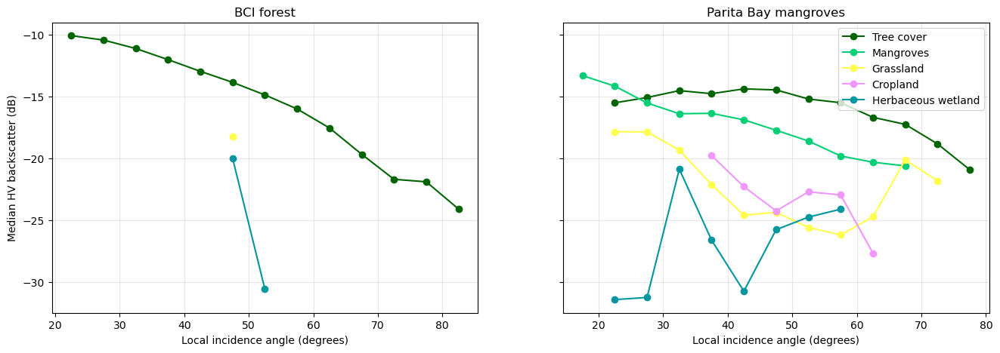

In [19]:
pixels['incidence_bin'] = (pixels.incidence // 5) * 5 + 2.5
# water is excluded: its backscatter is close to the noise level of the radar
classes = ['Tree cover', 'Mangroves', 'Grassland', 'Cropland', 'Herbaceous wetland']
fig, axes = plt.subplots(1, 2, figsize=(16, 5), sharey=True)
for ax, (site, df) in zip(axes, pixels.groupby('site', sort=False)):
    for cls in classes:
        d = df[df.land_cover == cls]
        stats = d.groupby('incidence_bin').HV_dB.agg(['median', 'size'])
        stats = stats[stats['size'] > 500]
        if len(stats):
            ax.plot(stats.index, stats['median'], 'o-',
                    color=lc_colors[{v: k for k, v in worldcover_classes.items()}[cls]],
                    label=cls)
    ax.set_title(site)
    ax.set_xlabel('Local incidence angle (degrees)')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('Median HV backscatter (dB)')
axes[1].legend()
plt.show()

The backscatter of all classes decreases with the incidence angle. The local incidence angle ranges from about 10° to 90°, because it includes the slopes of the hills. The backscatter is not corrected for terrain slope, and as such the forest on slopes facing the radar (low local incidence) is brighter than on slopes facing away. 

We compare the ecosystems median values below. We use only the pixels with a local incidence angle between 40-55 degrees.

In [20]:
inc_min, inc_max = 40, 55
sel = pixels[pixels.incidence.between(inc_min, inc_max) & pixels.land_cover.isin(classes)].copy()
sel['group'] = sel.site.str.split(' ').str[0] + ': ' + sel.land_cover
order = [g for g in ['BCI: Tree cover', 'Parita: Tree cover', 'Parita: Mangroves',
                     'Parita: Herbaceous wetland', 'Parita: Grassland', 'Parita: Cropland']
         if g in set(sel.group)]
summary = sel.groupby('group').agg(pixels=('HV_dB', 'size'), HH_dB=('HH_dB', 'median'),
                                   HV_dB=('HV_dB', 'median'), VV_dB=('VV_dB', 'median'),
                                   RVI=('RVI', 'median'), coherence=('coherence', 'median'))
summary.loc[order].round(2)

,pixels,HH_dB,HV_dB,VV_dB,RVI,coherence
group,,,,,,
BCI: Tree cover,254977,-8.57,-13.900000,-9.140000,0.91,0.36
Parita: Tree cover,292000,-8.39,-14.700000,-9.880000,0.81,0.34
Parita: Mangroves,611740,-10.71,-17.620001,-11.980000,0.73,0.39
Parita: Herbaceous wetland,246553,-16.59,-25.879999,-16.469999,0.42,0.40
Parita: Grassland,789942,-15.74,-25.010000,-15.920000,0.43,0.48
Parita: Cropland,189949,-14.76,-22.719999,-14.560000,0.51,0.62


We plot the statistics as box plots.

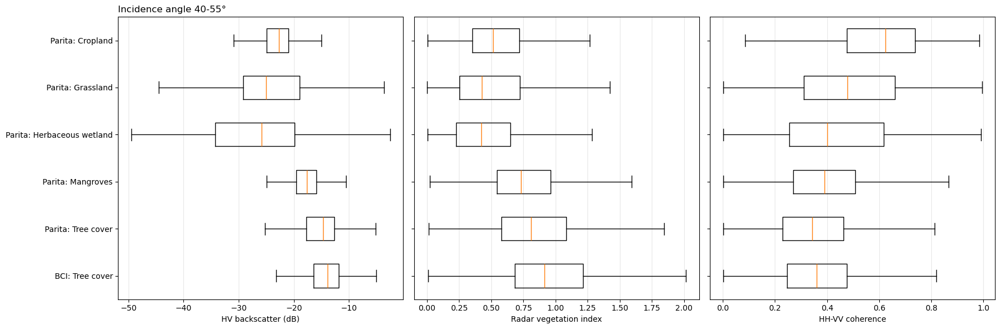

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for ax, (col, label) in zip(axes, [('HV_dB', 'HV backscatter (dB)'),
                                   ('RVI', 'Radar vegetation index'),
                                   ('coherence', 'HH-VV coherence')]):
    data = [sel.loc[sel.group == g, col].dropna() for g in order]
    ax.boxplot(data, orientation='horizontal', showfliers=False)
    ax.set_yticks(range(1, len(order) + 1), order)
    ax.set_xlabel(label)
    ax.grid(alpha=0.3, axis='x')
axes[0].set_title(f'Incidence angle {inc_min}-{inc_max}°', loc='left')
plt.tight_layout()
plt.show()

As we see above, forests have the highest HV backscatter and RVI because the signature of strong scattering in a tall complex canopy. The older forest of BCI is slightly brighter than the tree cover at Parita Bay. Mangroves have a lower HV backscatter and RVI than the forests, consistent with a smaller woody structure in the coastal mangroves. Grassland, cropland, and herbaceous wetlands have a much lower HV backscatter and RVI. Cropland has the highest HH-VV coherence, as its scattering is dominated by the soil surface.

### Phase difference

The HH-VV phase difference distinguishes double-bounce scattering (around 180 degrees) from surface and volume scattering (around 0 degrees). We plot its distribution for each class.

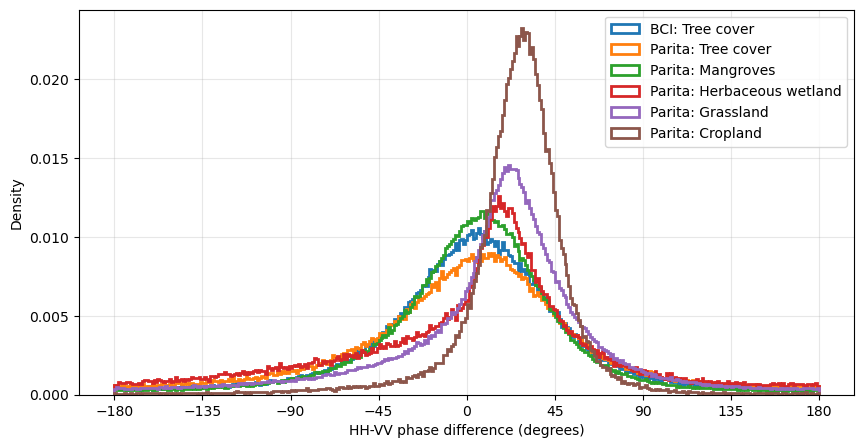

In [22]:
fig, ax = plt.subplots(figsize=(10, 5))
bins = np.arange(-180, 181, 1)
for g in order:
    d = sel.loc[sel.group == g, 'phase_diff'].dropna()
    ax.hist(d, bins=bins, density=True, 
            histtype='step', lw=2, label=g)
ax.set_xlabel('HH-VV phase difference (degrees)')
ax.set_ylabel('Density')
ax.set_xticks(np.arange(-180, 181, 45))
ax.legend()
ax.grid(alpha=0.3)
plt.show()

The vegetation classes have broad phase distributions, as expected for the random scattering of canopies, while cropland and grassland have narrower peaks, typical of surface scattering. None of the classes peaks near 180, the mangroves of Parita Bay are dominated by volume scattering rather than by double bounce between trunks and water. The double-bounce signal of mangroves is strongest when the forest floor is flooded.

## Export

We save the backscatter (dB) and structure indicators of each study area as a multi-band GeoTIFF, for use in a GIS later.

In [23]:
for site, s in sites.items():
    layers = {'HH_dB': db(s['HHHH']), 'HV_dB': db(s['HVHV']), 'VV_dB': db(s['VVVV']),
              'RVI': s['RVI'], 'coherence': s['coherence'], 'incidence_deg': s['inc']}
    stack = xr.concat([v.astype('float32') for v in layers.values()], dim='band')
    stack.attrs['long_name'] = list(layers)
    out = f"data/{s['line']}_{site.split(' ')[0]}_polsar.tif"
    stack.rio.write_crs('EPSG:4326').rio.write_nodata(np.nan).rio.to_raster(out,
                                                                            tiled=True,
                                                                            compress='DEFLATE')
    print(f"Saved {out}")

Saved data/PanCan_20012_26007_004_260505_L090_CX_01_BCI_polsar.tif
Saved data/pchame_06021_26008_022_260506_L090_CX_01_Parita_polsar.tif


## Compare with NISAR Satellite Data

The **NASA-ISRO Synthetic Aperture Radar ([NISAR](https://www.earthdata.nasa.gov/data/platforms/space-based-platforms/nisar))** satellite, launched in July 2025, carries an L-band radar similar to UAVSAR and observes almost all land surfaces every 12 days. 

We use the NISAR Level 2 Geocoded Polarimetric Covariance (GCOV)](https://doi.org/10.5067/NIL2GCOV-P1) product, which is the satellite counterpart of the UAVSAR PolSAR `.grd` files. Over Panama, NISAR acquires dual-polarization data (HH and HV) at 10 m resolution. The data released so far are **provisional**: their calibration is still being refined, so the values may change in later versions.

### Search NISAR GCOV granules

We search for GCOV granules over both study areas in the months after the UAVSAR flights.

In [24]:
# bounding box for both study areas (west, south, east, north)
both_sites = (-80.56, 8.16, -79.825, 9.185)
nisar = earthaccess.search_data(short_name='NISAR_L2_GCOV_PROVISIONAL_V1',
                                bounding_box=both_sites,
                                temporal=('2026-05-01', '2026-07-31'))

def nisar_details(g):
    """Returns the time, track, direction, and frame of a NISAR granul."""
    umm = g['umm']
    attrs = {a['Name']: a['Values'][0] for a in umm.get('AdditionalAttributes', [])}
    return {'granule': umm['GranuleUR'],
            'start_time': umm['TemporalExtent']['RangeDateTime']['BeginningDateTime'][:16],
            'track': attrs.get('TRACK_NUMBER'), 'direction': attrs.get('ASCENDING_DESCENDING'),
            'frame': attrs.get('FRAME_NUMBER'), 'polarizations': attrs.get('FREQUENCY_A_POLARIZATION_CONCAT'),
            'size_gb': round(g['size'] / 1024, 1)}

nisar_gdf = gpd.GeoDataFrame([nisar_details(g) for g in nisar],
                             geometry=gpd.GeoSeries(nisar, crs='EPSG:4326'))
nisar_gdf['covers_both_sites'] = nisar_gdf.geometry.apply(
    lambda geom: all(geom.contains(box(*s['bounds'])) for s in sites.values()))
nisar_gdf.drop(columns='geometry').sort_values('start_time')


,granule,start_time,track,direction,frame,polarizations,size_gb,covers_both_sites
0,NISAR_L2_PR_GCOV_023_040_D_084_4005_DHDH_A_202...,2026-06-16T23:44,40,DESCENDING,84,HH+HV,4.6,True
1,NISAR_L2_PR_GCOV_023_040_D_085_4005_DHDH_A_202...,2026-06-16T23:45,40,DESCENDING,85,HH+HV,2.7,False
2,NISAR_L2_PR_GCOV_023_076_A_006_4005_DHDH_A_202...,2026-06-19T10:56,76,ASCENDING,6,HH+HV,1.7,False
3,NISAR_L2_PR_GCOV_023_076_A_006_4005_DHDH_A_202...,2026-06-19T10:56,76,ASCENDING,6,HH+HV,2.1,False
4,NISAR_L2_PR_GCOV_023_141_D_084_4005_DHDH_A_202...,2026-06-23T23:53,141,DESCENDING,84,HH+HV,4.7,False
5,NISAR_L2_PR_GCOV_024_040_D_084_4005_DHDH_A_202...,2026-06-28T23:44,40,DESCENDING,84,HH+HV,4.8,True
6,NISAR_L2_PR_GCOV_024_076_A_006_4005_DHDH_A_202...,2026-07-01T10:56,76,ASCENDING,6,HH+HV,1.8,False
7,NISAR_L2_PR_GCOV_024_076_A_006_4005_DHDH_A_202...,2026-07-01T10:56,76,ASCENDING,6,HH+HV,2.1,False
8,NISAR_L2_PR_GCOV_024_141_D_084_4005_DHDH_A_202...,2026-07-05T23:53,141,DESCENDING,84,HH+HV,4.6,False
9,NISAR_L2_PR_GCOV_025_040_D_084_4005_DHDH_A_202...,2026-07-10T23:44,40,DESCENDING,84,HH+HV,4.8,True


NISAR passes over Panama on several tracks, both ascending (night) and descending (evening). The first acquisitions over our study areas are from mid-June 2026, about six weeks after the UAVSAR flights. We use the first granule that covers both study areas.

Each granule includes a quick-look image of the frame.

In [25]:
nisar_gdf = nisar_gdf.sort_values('start_time')
granule = [g for g in nisar if g['umm']['GranuleUR'] == nisar_gdf[nisar_gdf.covers_both_sites].granule.iloc[0]][0]
granule

Collection: {'ShortName': 'NISAR_L2_GCOV_PROVISIONAL_V1', 'Version': '1'}
Spatial coverage: {'GranuleLocalities': ['Land', 'North America'], 'HorizontalSpatialDomain': {'Geometry': {'GPolygons': [{'Boundary': {'Points': [{'Latitude': 10.07638, 'Longitude': -80.27757}, {'Latitude': 8.10901, 'Longitude': -80.73514}, {'Latitude': 7.59404, 'Longitude': -78.51223}, {'Latitude': 9.55363, 'Longitude': -78.04429}, {'Latitude': 10.07638, 'Longitude': -80.27757}]}}]}}}
Temporal coverage: {'RangeDateTime': {'BeginningDateTime': '2026-06-16T23:44:48.000000Z', 'EndingDateTime': '2026-06-16T23:45:20.999342Z'}}
Size(MB): 4662.970445632935
Data: ['https://nisar.asf.earthdatacloud.nasa.gov/NISAR/NISAR_L2_GCOV_PROVISIONAL_V1/NISAR_L2_PR_GCOV_023_040_D_084_4005_DHDH_A_20260616T234448_20260616T234520_P05023_F_F_J_001/NISAR_L2_PR_GCOV_023_040_D_084_4005_DHDH_A_20260616T234448_20260616T234520_P05023_F_F_J_001.h5']

### Open the GCOV file

A GCOV granule is an HDF5 file of about 5 GB. We open it remotely with `h5py`, using 4 MB read blocks, and only read the parts we need. The backscatter layers of the main frequency band (`frequencyA`, with a 40 MHz bandwidth over Panama) are in the group `/science/LSAR/GCOV/grids/frequencyA`.


In [26]:
nisar_url = [u for u in granule.data_links() if u.endswith('.h5')][0]
nisar_h5 = h5py.File(fs.open(nisar_url, block_size=4 * 1024 * 1024, cache_type='blockcache'), 'r')
grid = nisar_h5['science/LSAR/GCOV/grids/frequencyA']
for name, ds in grid.items():
    print(f"{name:25s} {str(ds.shape):16s} {ds.dtype}")


HHHH                      (33048, 33768)   float32
HVHV                      (33048, 33768)   float32
inputDataExceptionMask    (33048, 33768)   uint8
listOfCovarianceTerms     (2,)             |S4
listOfPolarizations       (2,)             |S2
mask                      (33048, 33768)   uint8
numberOfLooks             (33048, 33768)   float32
numberOfSubSwaths         ()               uint8
projection                ()               uint32
rtcGammaToSigmaFactor     (33048, 33768)   float32
xCoordinateSpacing        ()               float64
xCoordinates              (33768,)         float64
yCoordinateSpacing        ()               float64
yCoordinates              (33048,)         float64


| Dataset | Description |
|---|---|
| `HHHH`, `HVHV` | Backscatter of the HH and HV channels, as γ0 (gamma nought) in linear power units, with radiometric terrain correction (RTC) |
| `rtcGammaToSigmaFactor` | Factor to convert γ0 to σ0, which accounts for the local terrain |
| `mask` | Valid pixels -  0 for pixels from partially focused radar data, 255 outside the swath |
| `numberOfLooks` | Number of radar samples averaged in each pixel |
| `xCoordinates`, `yCoordinates`, `projection` | Pixel center coordinates (m) in the projection given as an EPSG code |

Unlike the UAVSAR GRD product, NISAR GCOV is corrected for terrain: the γ0 values are normalized by the actual area of the terrain seen by the radar, which removes most of the brightness differences between slopes facing toward and away from the radar.


In [27]:
nisar_crs = pyproj.CRS.from_epsg(int(grid['projection'][()]))
nisar_x = grid['xCoordinates'][:]
nisar_y = grid['yCoordinates'][:]
print(f"Projection: {nisar_crs.name}, pixel size: {grid['xCoordinateSpacing'][()]} m, "
      f"grid: {len(nisar_y)} x {len(nisar_x)} pixels")


Projection: WGS 84 / UTM zone 17N, pixel size: 10.0 m, grid: 33048 x 33768 pixels


### Read the study areas

The function below converts the bounds of a study area to the NISAR projection, finds the corresponding rows and columns, and reads only those pixels. We convert γ0 to σ0 with the `rtcGammaToSigmaFactor`, to compare with the UAVSAR σ0, and remove invalid pixels with the mask.


In [28]:
def read_gcov(bounds):
    """Reads HH and HV sigma0 (linear) of the NISAR GCOV grid within bounds (lon/lat)."""
    to_utm = pyproj.Transformer.from_crs('EPSG:4326', nisar_crs, always_xy=True)
    west, south, east, north = bounds
    xs, ys = to_utm.transform([west, east, west, east], [south, south, north, north])
    c0, c1 = np.searchsorted(nisar_x, min(xs)), np.searchsorted(nisar_x, max(xs))
    r0, r1 = np.searchsorted(-nisar_y, -max(ys)), np.searchsorted(-nisar_y, -min(ys))
    mask = grid['mask'][r0:r1, c0:c1]
    factor = grid['rtcGammaToSigmaFactor'][r0:r1, c0:c1]
    valid = (mask > 0) & (mask < 255)
    out = {}
    for term in ['HHHH', 'HVHV']:
        sigma0 = np.where(valid, grid[term][r0:r1, c0:c1] * factor, np.nan)
        out[term] = xr.DataArray(sigma0, dims=('y', 'x'),
                                 coords={'y': nisar_y[r0:r1], 'x': nisar_x[c0:c1]}
                                 ).rio.write_crs(nisar_crs).rio.write_nodata(np.nan)
    return out

for site, s in sites.items():
    s['nisar'] = read_gcov(s['bounds'])
    print(f"{site}: {dict(s['nisar']['HVHV'].sizes)}")

BCI forest: {'y': 555, 'x': 551}
Parita Bay mangroves: {'y': 1660, 'x': 1434}


### Compare the images

We plot the HV backscatter of UAVSAR (May 2026) next to that of NISAR (June 2026) for both study areas, on the same color scale.


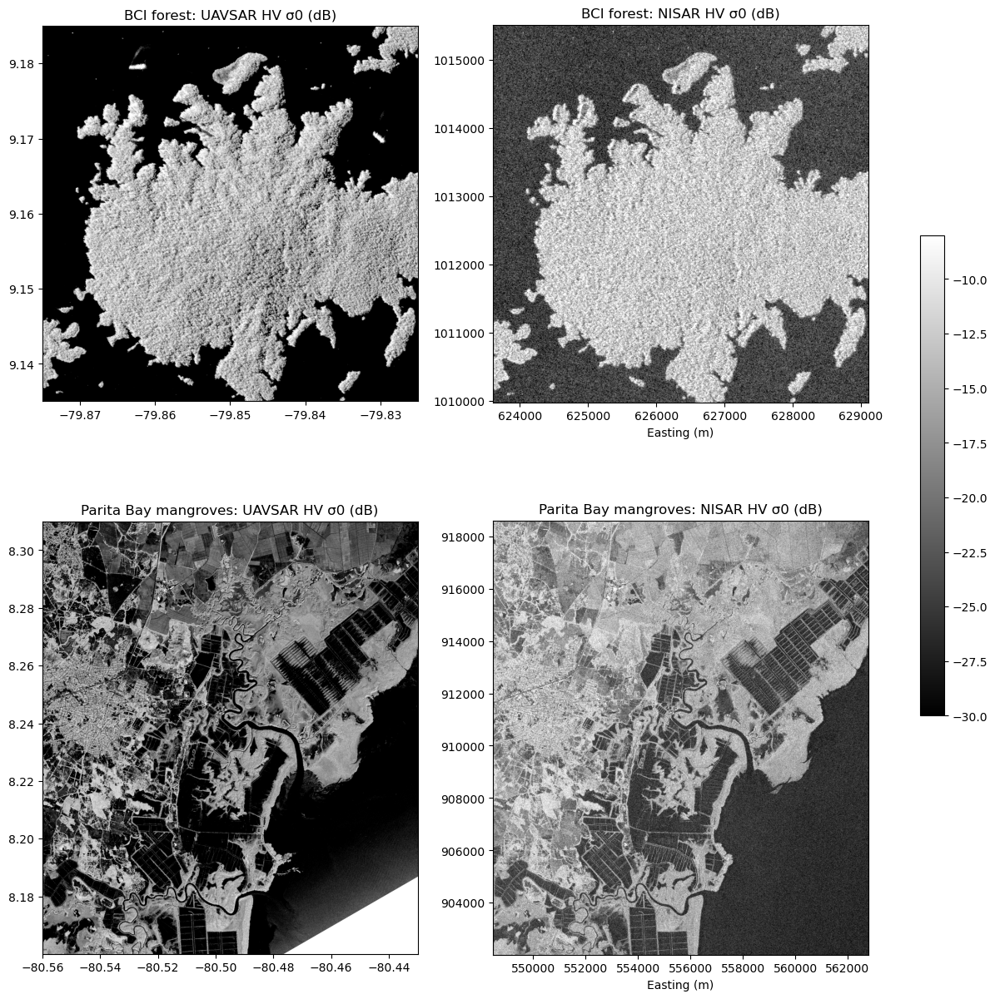

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(16, 15))
for row, (site, s) in zip(axes, sites.items()):
    im = row[0].imshow(db(s['HVHV']), extent=extent(s['HVHV']), vmin=-30, vmax=-8, cmap='gray')
    row[0].set_title(f"{site}: UAVSAR HV σ0 (dB)")
    nhv = s['nisar']['HVHV']
    row[1].imshow(db(nhv), extent=extent(nhv), vmin=-30, vmax=-8, cmap='gray')
    row[1].set_title(f"{site}: NISAR HV σ0 (dB)")
    row[1].set_xlabel('Easting (m)')
    row[1].ticklabel_format(style='plain')
fig.colorbar(im, ax=axes, shrink=0.5)
plt.show()

The two sensors show the same landscape: the bright forest of BCI and the dark lake around it, and at Parita Bay the bright mangroves along the channels, the dark shrimp ponds, and the town of Aguadulce. The forest of BCI has less texture in NISAR, because NISAR is corrected for terrain, and UAVSAR is not.
The water is much brighter in NISAR than in UAVSAR. This is the noise level of NISAR, which is not subtracted in this provisional product (`noiseCorrectionApplied` is `False` in the file metadata). NISAR cannot measure HV backscatter below about -25 dB.

### Compare by land cover

To compare the two sensors pixel by pixel, we put the UAVSAR backscatter on the 10 m NISAR grid, averaging the UAVSAR pixels within each NISAR pixel (`Resampling.average`). We also put the WorldCover land cover on the NISAR grid. We then compute the median backscatter of each land cover class, and the dual-polarization radar vegetation index, 4 HV / (HH + HV), which can be computed from both sensors.

In [30]:
rows = []
for site, s in sites.items():
    nisar_grid = s['nisar']['HVHV']
    uav = {term: s[term].rio.write_nodata(np.nan).rio.reproject_match(nisar_grid, resampling=Resampling.average)
           for term in ['HHHH', 'HVHV']}
    s['uavsar_on_nisar'] = uav
    lc = worldcover(s['bounds'], nisar_grid)
    for sensor, d in [('UAVSAR', uav), ('NISAR', s['nisar'])]:
        df = pd.DataFrame({'land_cover': lc.values.ravel(),
                           'HH_dB': db(d['HHHH']).values.ravel(), 'HV_dB': db(d['HVHV']).values.ravel(),
                           'RVI_dual': (4 * d['HVHV'] / (d['HHHH'] + d['HVHV'])).values.ravel()})
        df['site'], df['sensor'] = site.split(' ')[0], sensor
        rows.append(df.dropna())
both = pd.concat(rows, ignore_index=True)
both['land_cover'] = both.land_cover.map(worldcover_classes)
compare_classes = ['Tree cover', 'Mangroves', 'Grassland', 'Cropland', 'Herbaceous wetland', 'Permanent water']
df = (both[both.land_cover.isin(compare_classes)]
         .groupby(['site', 'land_cover', 'sensor'])[['HH_dB', 'HV_dB', 'RVI_dual']].median()
         .unstack('sensor').round(2))
df = df[[(m, sensor) for m in ['HH_dB', 'HV_dB', 'RVI_dual'] for sensor in ['UAVSAR', 'NISAR']]]
df


HH_dB         HV_dB            RVI_dual      
sensor                        UAVSAR  NISAR UAVSAR      NISAR   UAVSAR NISAR
site   land_cover                                                           
BCI    Grassland           -9.960000  -9.27 -17.40 -16.309999     0.63  0.68
       Herbaceous wetland -12.790000 -12.08 -21.98 -18.459999     0.58  0.86
       Permanent water    -33.369999 -18.32 -40.52 -23.990000     0.64  0.85
       Tree cover          -8.830000  -8.06 -14.10 -12.870000     0.89  1.00
Parita Cropland           -14.860000  -8.12 -22.67 -15.660000     0.57  0.57
       Grassland          -14.830000  -9.73 -23.57 -17.250000     0.48  0.61
       Herbaceous wetland -15.130000 -12.33 -24.91 -20.730000     0.39  0.60
       Mangroves           -9.880000  -8.80 -16.90 -15.010000     0.68  0.77
       Permanent water    -15.620000 -17.25 -31.77 -25.430000     0.09  0.53
       Tree cover          -8.410000  -7.12 -14.65 -12.860000     0.75  0.82

We also compare the two sensors on a coarser 100 m grid, which reduces speckle and the effect of small differences in geolocation. We average 10 × 10 NISAR pixels and plot the UAVSAR HV backscatter against the NISAR HV backscatter, colored by the main land cover class.


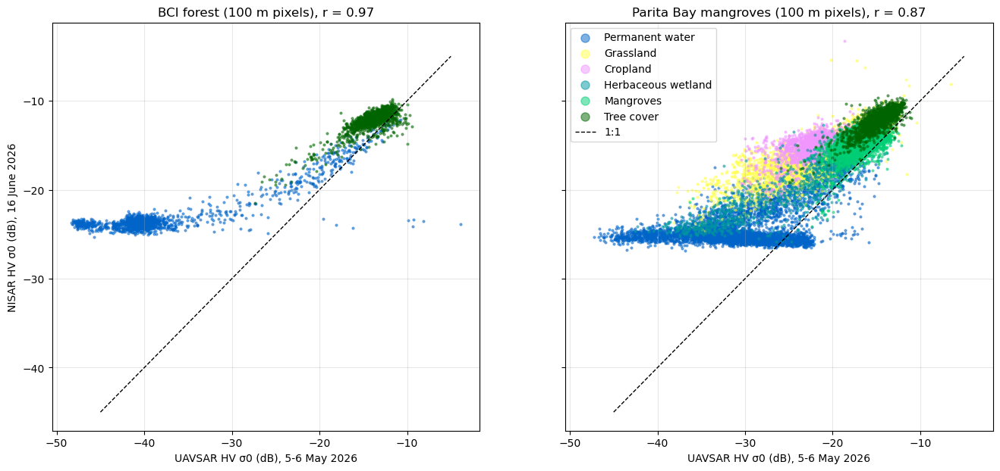

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7), sharex=True, sharey=True)
for ax, (site, s) in zip(axes, sites.items()):
    coarse = lambda da: da.coarsen(x=10, y=10, boundary='trim').mean()
    u = db(coarse(s['uavsar_on_nisar']['HVHV'])).values.ravel()
    n = db(coarse(s['nisar']['HVHV'])).values.ravel()
    lc = worldcover(s['bounds'],
                    s['nisar']['HVHV']).coarsen(x=10, y=10, boundary='trim').median().values.ravel()
    ok = np.isfinite(u) & np.isfinite(n)
    for lc_code in [80, 30, 40, 90, 95, 10]:
        in_class = ok & (lc == lc_code)
        if in_class.sum() > 20:
            ax.scatter(u[in_class], n[in_class], s=4, alpha=0.5, color=lc_colors[lc_code],
                       label=worldcover_classes[lc_code])
    ax.plot([-45, -5], [-45, -5], 'k--', lw=1, label='1:1')
    ax.set_title(f"{site} (100 m pixels), r = {np.corrcoef(u[ok], n[ok])[0, 1]:.2f}")
    ax.set_xlabel('UAVSAR HV σ0 (dB), 5-6 May 2026')
    ax.grid(alpha=0.3)
axes[0].set_ylabel('NISAR HV σ0 (dB), 16 June 2026')
axes[1].legend(markerscale=4)
plt.show()

For forests and mangroves, the NISAR HV backscatter is slightly higher than UAVSAR for tree cover and mangroves at both sites. For grassland, cropland, and herbaceous wetlands at Parita Bay, where these classes cover large areas, NISAR is brighter than UAVSAR, as shown by the points above the 1:1 line. NISAR might have collected during the rainy season. Growing grass and crops and wetter soils increase the backscatter of these open areas, while forests changes less. NISAR captures the contrasts in vegetation structure that UAVSAR shows in more detail.